JS05 Praktikum 1 - HDBSCAN vs DBSCAN: scale invariance & multi-scale density.

Catatan: paket `hdbscan` (PyPI) tidak tersedia di venv ini, dipakai
sklearn.cluster.HDBSCAN (sklearn >= 1.3). Perbedaan API: tidak ada
dbscan_clustering(); penggantinya lihat praktikum-2.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("hdbscan_vs_dbscan.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js05-klasterisasi-hierarki\praktikum-1


In [2]:
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score, silhouette_score

OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(parents=True, exist_ok=True)
ROWS = []

In [3]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    """Plot cluster: noise = x hitam, ukuran marker ~ probabilitas keanggotaan."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = np.asarray(labels) if labels is not None else np.ones(len(X), dtype=int)
    probabilities = probabilities if probabilities is not None else np.ones(len(X))
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        idx = (labels == k).nonzero()[0]
        for ci in idx:
            ax.plot(X[ci, 0], X[ci, 1], "x" if k == -1 else "o",
                    markerfacecolor=tuple(col), markeredgecolor="k",
                    markersize=4 if k == -1 else 1 + 5 * probabilities[ci])

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    title = f"{'True' if ground_truth else 'Estimated'} number of clusters: {n_clusters}"
    if parameters is not None:
        title += " | " + ", ".join(f"{k}={v}" for k, v in parameters.items())
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def score(X, labels, labels_true=None, tag=""):
    """Cetak & simpan metrik internal (silhouette) + eksternal (ARI)."""
    labels = np.asarray(labels)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    sil = np.nan
    if 1 < n_clusters < len(labels):
        sil = silhouette_score(X, labels)
    ari = adjusted_rand_score(labels_true, labels) if labels_true is not None else np.nan
    print(f"  {tag:<28} cluster={n_clusters} noise={n_noise:>3} "
          f"silhouette={sil:.4f} ARI={ari:.4f}")
    ROWS.append(dict(eksperimen=tag, n_cluster=n_clusters, n_noise=n_noise,
                     silhouette=sil, ari=ari))
    return sil, ari

In [4]:
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / name, dpi=110)
    print(f"  -> output/{name}")

[Langkah 3] Dataset 3 cluster Gaussian (std 0.4 / 0.1 / 0.75)


  -> output/p1_dataset_ground_truth.png


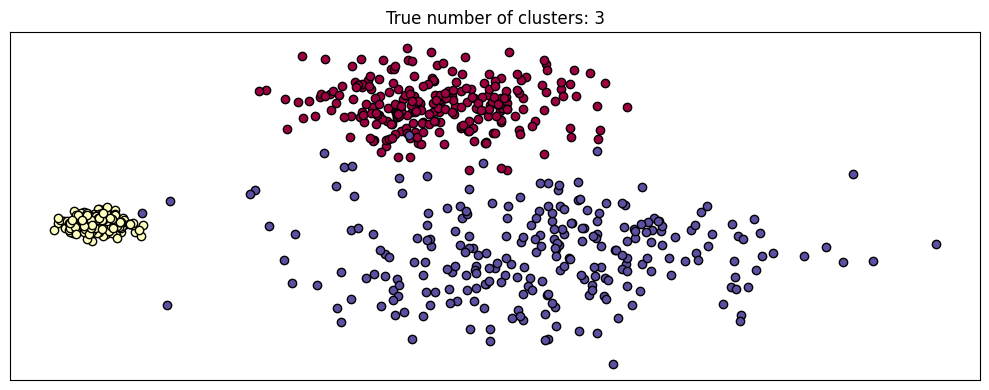

In [5]:
# ---------------------------------------------------------------- Langkah 3
print("[Langkah 3] Dataset 3 cluster Gaussian (std 0.4 / 0.1 / 0.75)")
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(n_samples=750, centers=centers,
                            cluster_std=[0.4, 0.1, 0.75], random_state=0)
fig, ax = plt.subplots(figsize=(10, 4))
plot(X, labels_true, ground_truth=True, ax=ax)
save(fig, "p1_dataset_ground_truth.png")

[Langkah 4] DBSCAN eps=0.3 tidak invariant terhadap skala


  DBSCAN eps=0.3 scale=1       cluster=3 noise= 24 silhouette=0.6652 ARI=0.9242


  DBSCAN eps=0.3 scale=0.5     cluster=1 noise=  2 silhouette=nan ARI=0.0000


  DBSCAN eps=0.3 scale=3       cluster=11 noise=320 silhouette=0.0663 ARI=0.5903


  -> output/p1_dbscan_skala.png


  DBSCAN eps=0.9 scale=3       cluster=3 noise= 24 silhouette=0.6652 ARI=0.9242


  -> output/p1_dbscan_eps0.9_scale3.png


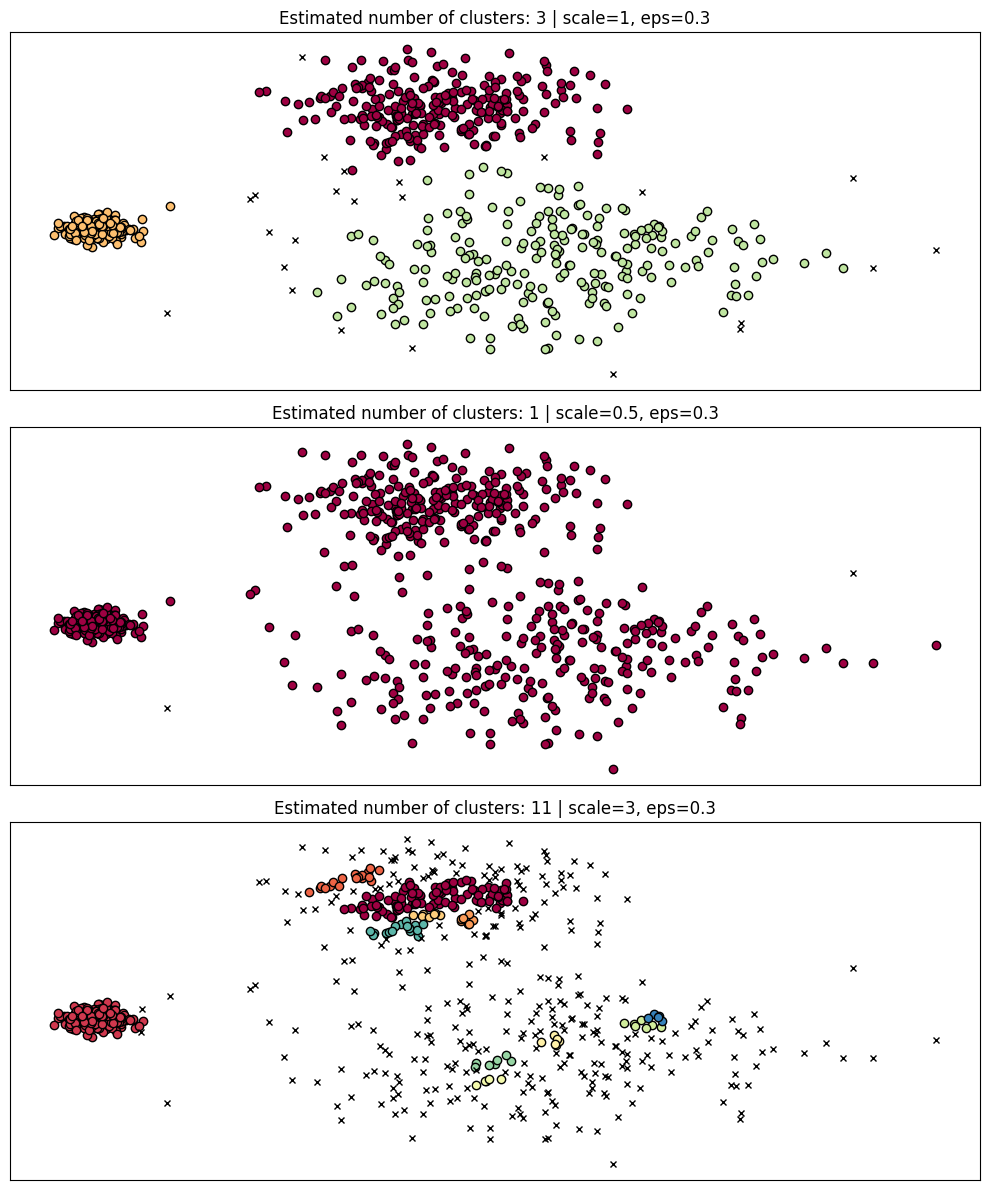

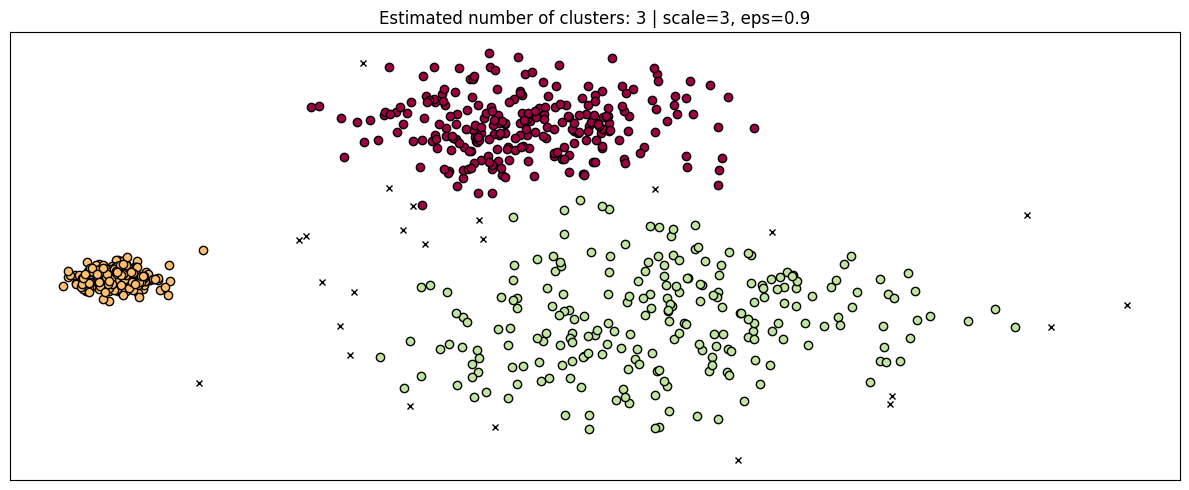

In [6]:
# ---------------------------------------------------------------- Langkah 4
print("[Langkah 4] DBSCAN eps=0.3 tidak invariant terhadap skala")
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, scale in enumerate([1, 0.5, 3]):
    dbs = DBSCAN(eps=0.3).fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[i])
    score(X * scale, dbs.labels_, labels_true, f"DBSCAN eps=0.3 scale={scale}")
save(fig, "p1_dbscan_skala.png")

fig, ax = plt.subplots(figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=ax)
score(3 * X, dbs.labels_, labels_true, "DBSCAN eps=0.9 scale=3")
save(fig, "p1_dbscan_eps0.9_scale3.png")

[Langkah 5] HDBSCAN tetap stabil pada berbagai skala


  HDBSCAN scale=1              cluster=3 noise= 40 silhouette=0.6548 ARI=0.8941


  HDBSCAN scale=0.5            cluster=3 noise= 40 silhouette=0.6548 ARI=0.8941


  HDBSCAN scale=3              cluster=3 noise= 40 silhouette=0.6548 ARI=0.8941


  -> output/p1_hdbscan_skala.png


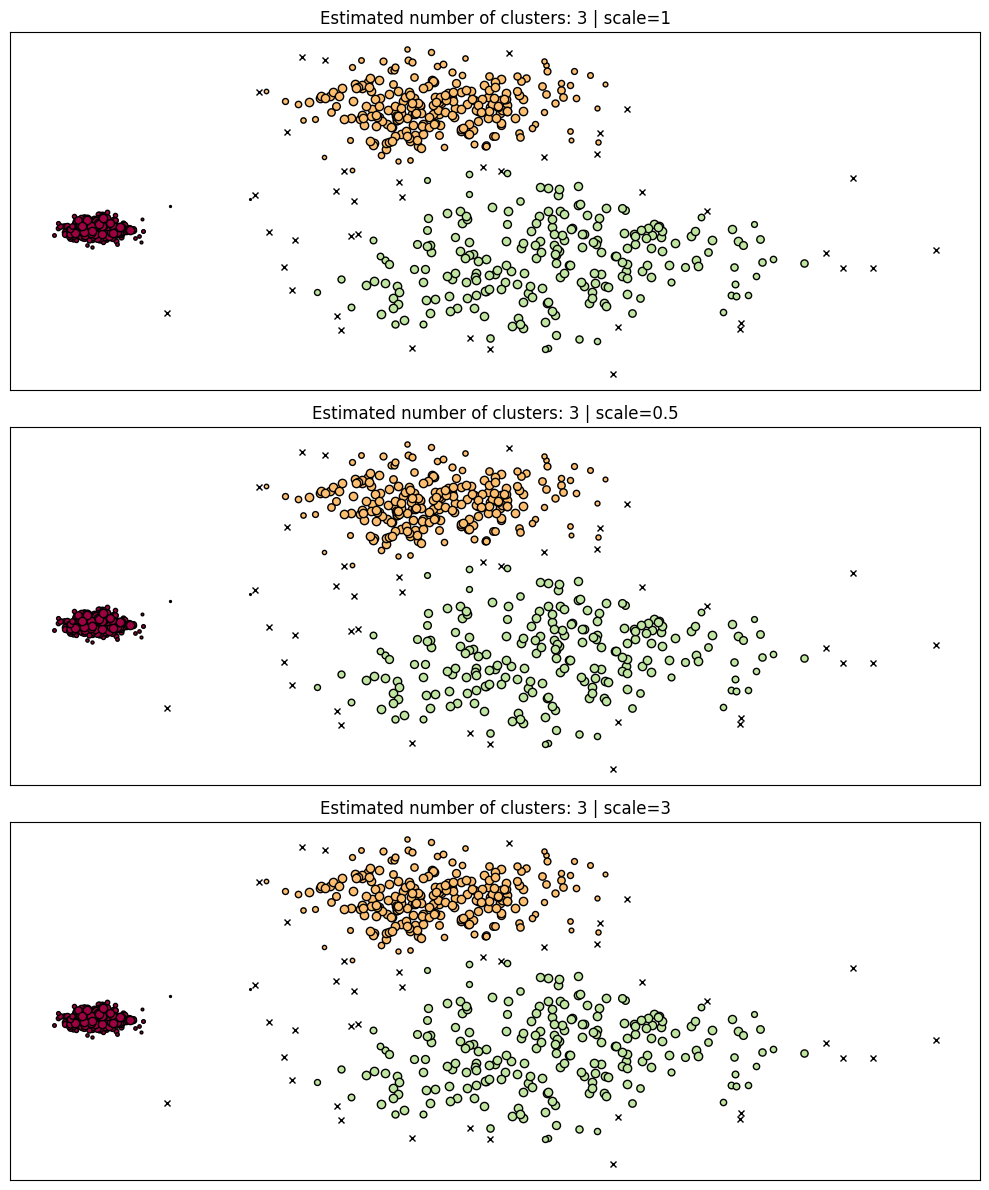

In [7]:
# ---------------------------------------------------------------- Langkah 5
print("[Langkah 5] HDBSCAN tetap stabil pada berbagai skala")
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, scale in enumerate([1, 0.5, 3]):
    hdb = HDBSCAN().fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, {"scale": scale}, ax=axes[i])
    score(X * scale, hdb.labels_, labels_true, f"HDBSCAN scale={scale}")
save(fig, "p1_hdbscan_skala.png")

[Langkah 6] Dataset multi-skala (kepadatan berbeda: std 0.2/0.35/1.35/1.35)


  -> output/p1_multiskala_ground_truth.png


  DBSCAN eps=0.7 multiskala    cluster=3 noise= 23 silhouette=0.6315 ARI=0.6464


  DBSCAN eps=0.3 multiskala    cluster=14 noise=206 silhouette=0.2181 ARI=0.4041


  -> output/p1_multiskala_dbscan.png


  HDBSCAN multiskala           cluster=4 noise= 32 silhouette=0.5716 ARI=0.9212


  -> output/p1_multiskala_hdbscan.png

[selesai] 10 eksperimen -> output/p1_metrik.csv


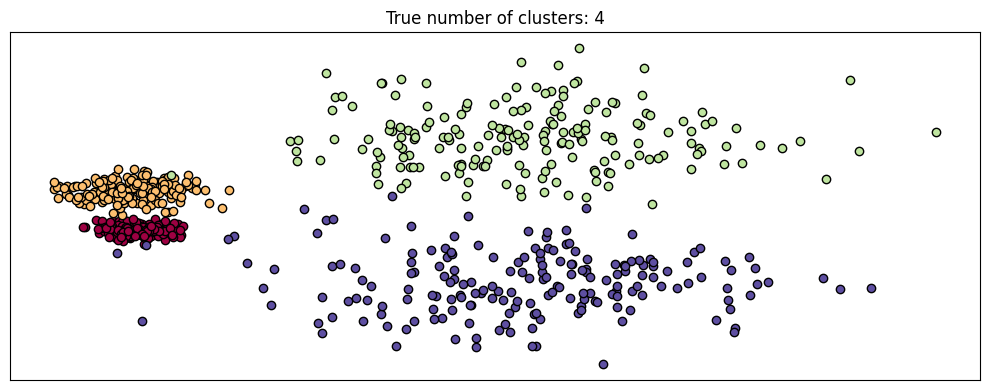

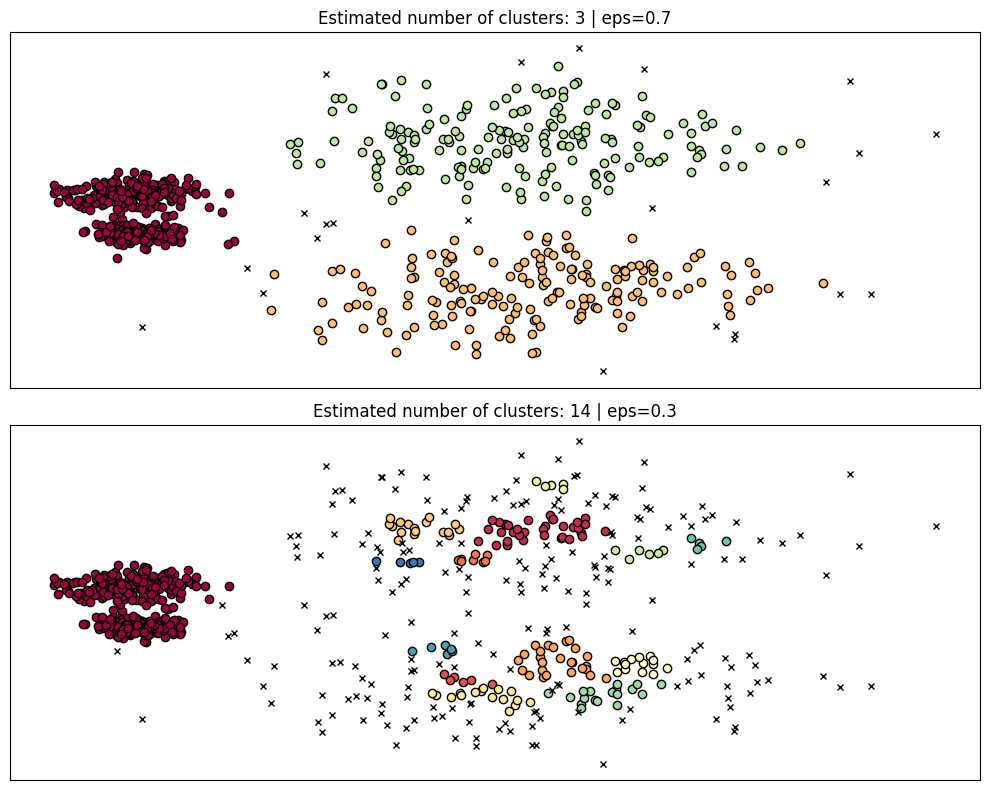

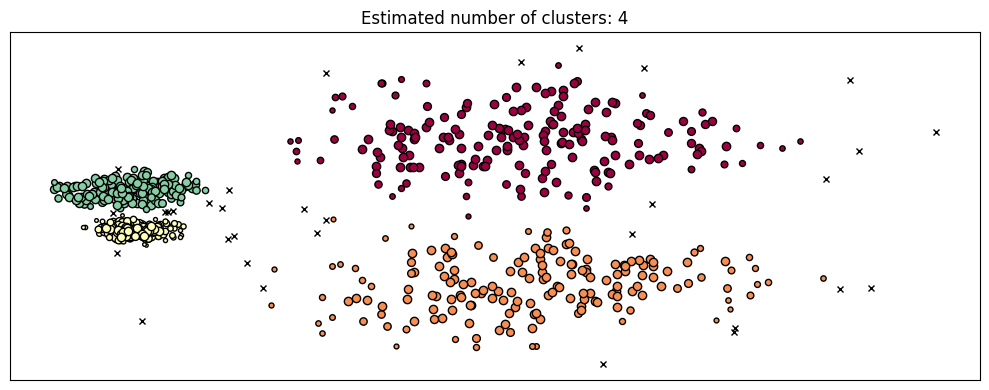

In [8]:
# ---------------------------------------------------------------- Langkah 6
print("[Langkah 6] Dataset multi-skala (kepadatan berbeda: std 0.2/0.35/1.35/1.35)")
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
Xm, labels_m = make_blobs(n_samples=750, centers=centers,
                          cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0)
fig, ax = plt.subplots(figsize=(10, 4))
plot(Xm, labels_m, ground_truth=True, ax=ax)
save(fig, "p1_multiskala_ground_truth.png")

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
for i, eps in enumerate([0.7, 0.3]):
    dbs = DBSCAN(eps=eps).fit(Xm)
    plot(Xm, dbs.labels_, parameters={"eps": eps}, ax=axes[i])
    score(Xm, dbs.labels_, labels_m, f"DBSCAN eps={eps} multiskala")
save(fig, "p1_multiskala_dbscan.png")

hdb = HDBSCAN().fit(Xm)
fig, ax = plt.subplots(figsize=(10, 4))
plot(Xm, hdb.labels_, hdb.probabilities_, ax=ax)
score(Xm, hdb.labels_, labels_m, "HDBSCAN multiskala")
save(fig, "p1_multiskala_hdbscan.png")

pd.DataFrame(ROWS).to_csv(OUT / "p1_metrik.csv", index=False)
print(f"\n[selesai] {len(ROWS)} eksperimen -> output/p1_metrik.csv")